# Student Risk: Exploratory Data Analysis

This notebook inspects the synthetic week-8 checkpoint dataset. The outcome is whether the week-10 assessment score is below 50. All plots are saved to `reports/figures/`. This analysis is exploratory and advisory; it does not automate grading, punishment, or admissions.

## Dataset overview

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw" / "students.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "students.csv"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
display(df.dtypes.rename("dtype").to_frame())

Dataset shape: (2400, 12)
Columns: ['student_id', 'term', 'attendance_pct', 'attendance_trend_3w', 'assignment_completion_rate', 'late_submission_rate', 'prev_score_1', 'prev_score_2', 'prev_score_3', 'days_since_last_submission', 'next_score', 'at_risk']


,student_id,term,attendance_pct,attendance_trend_3w,assignment_completion_rate,late_submission_rate,prev_score_1,prev_score_2,prev_score_3,days_since_last_submission,next_score,at_risk
0,T1-0001,1,83.120242,-6.949581,0.701659,0.226940,69.912586,74.583341,65.036782,7,69.416425,0
1,T1-0002,1,71.538105,0.403674,0.278219,0.436298,37.668876,38.782790,59.298051,10,58.986359,0
2,T1-0003,1,91.745102,6.192898,0.860365,0.109407,58.409617,74.283203,72.284105,4,94.419607,0
3,T1-0004,1,79.804487,-0.742304,0.547146,0.322367,75.240404,77.090475,64.943175,7,72.166460,0
4,T1-0005,1,70.766816,-1.994059,0.174497,0.617614,31.258859,47.472957,35.874511,7,43.427801,1


,dtype
student_id,str
term,int64
attendance_pct,float64
attendance_trend_3w,float64
assignment_completion_rate,float64
late_submission_rate,float64
prev_score_1,float64
prev_score_2,float64
prev_score_3,float64
days_since_last_submission,int64


## Data-quality checks

In [2]:
profile_columns = [column for column in df.columns if column != "student_id"]
quality_summary = pd.Series({
    "rows": len(df),
    "unique student IDs": df["student_id"].nunique(),
    "duplicate feature/label profiles (excluding ID)": df.duplicated(
        subset=profile_columns, keep="first"
    ).sum(),
    "missing prev_score_3": df["prev_score_3"].isna().sum(),
    "missing attendance_pct": df["attendance_pct"].isna().sum(),
    "attendance_pct > 100": (df["attendance_pct"] > 100).sum(),
    "days_since_last_submission < 0": (df["days_since_last_submission"] < 0).sum(),
    "historical score > 100": (df[["prev_score_1", "prev_score_2", "prev_score_3"]] > 100).sum().sum(),
})
display(quality_summary.rename("count").to_frame())

display(df.drop(columns="student_id").describe().T[["min", "max", "mean", "std"]])

,count
rows,2400
unique student IDs,2400
duplicate feature/label profiles (excluding ID),24
missing prev_score_3,121
missing attendance_pct,119
attendance_pct > 100,23
days_since_last_submission < 0,24
historical score > 100,25


,min,max,mean,std
term,1.000000,4.000000,2.500000,1.118267
attendance_pct,60.030346,105.000000,80.211250,7.402236
attendance_trend_3w,-16.816044,18.933498,-0.243493,4.995089
assignment_completion_rate,0.015999,0.976741,0.535448,0.219293
late_submission_rate,0.018067,0.940182,0.307099,0.177414
prev_score_1,11.237910,100.000000,62.017645,14.145667
prev_score_2,16.763977,105.000000,63.733697,14.583126
prev_score_3,11.965624,100.000000,63.429820,14.140341
days_since_last_submission,-3.000000,18.000000,5.932083,3.638404
next_score,3.602667,100.000000,64.517692,18.092117


## Target definition and class imbalance

Target: 1 when next_score < 50; otherwise 0
At-risk rate: 21.50%


,students
at_risk,
not at risk,1884
at risk,516


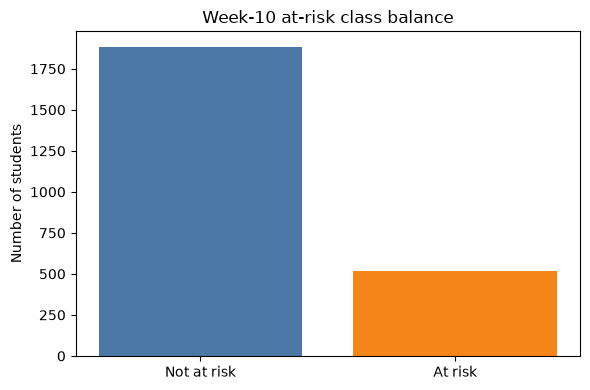

In [3]:
assert (df["at_risk"] == (df["next_score"] < 50).astype(int)).all()
class_counts = df["at_risk"].value_counts().reindex([0, 1], fill_value=0)
print("Target: 1 when next_score < 50; otherwise 0")
print("At-risk rate:", f"{df['at_risk'].mean():.2%}")
display(class_counts.rename(index={0: "not at risk", 1: "at risk"}).to_frame("students"))

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Not at risk", "At risk"], class_counts.to_numpy(), color=["#4C78A8", "#F58518"])
ax.set(title="Week-10 at-risk class balance", ylabel="Number of students")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "target_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** At-risk students are the minority class, so recall for this class should be prioritized when evaluating future models.

## Feature distributions by class

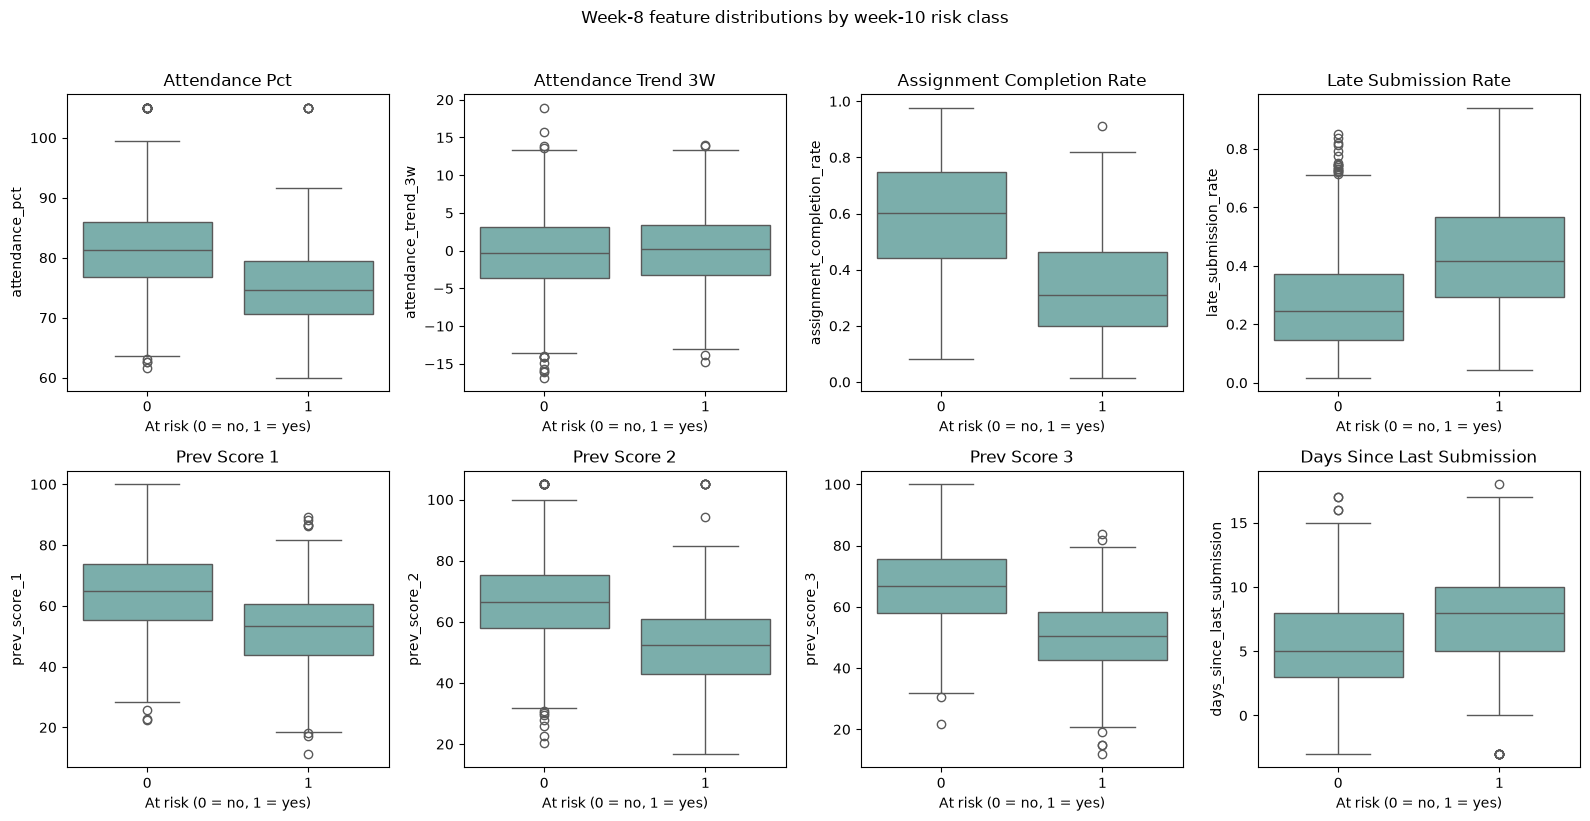

In [4]:
feature_columns = [
    "attendance_pct", "attendance_trend_3w", "assignment_completion_rate",
    "late_submission_rate", "prev_score_1", "prev_score_2", "prev_score_3",
    "days_since_last_submission",
]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for feature, ax in zip(feature_columns, axes.flat):
    sns.boxplot(data=df, x="at_risk", y=feature, ax=ax, color="#72B7B2")
    ax.set(title=feature.replace("_", " ").title(), xlabel="At risk (0 = no, 1 = yes)")
fig.suptitle("Week-8 feature distributions by week-10 risk class", y=1.02)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "feature_distributions_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** Prior scores, attendance, and completion show useful class separation, but overlap between classes means these indicators support check-ins rather than definitive judgments.

## Correlation heatmap

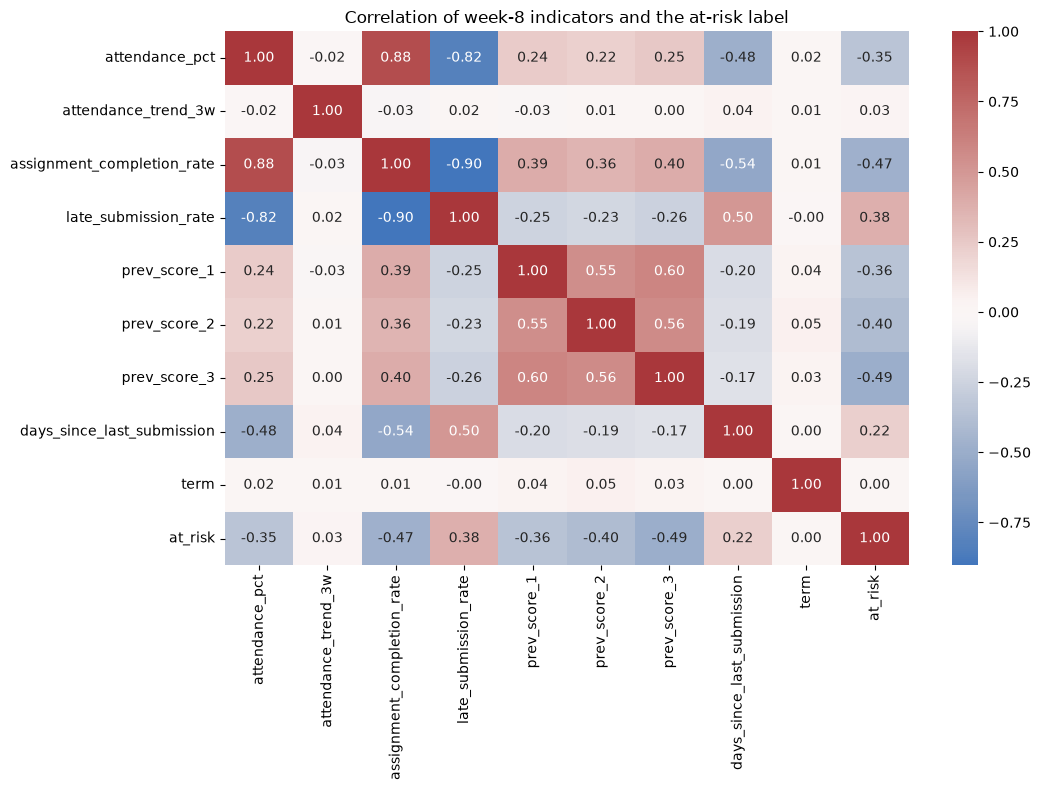

In [5]:
# The outcome score is intentionally omitted: it is unavailable at the week-8 checkpoint.
correlation_columns = feature_columns + ["term", "at_risk"]
correlations = df[correlation_columns].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(correlations, cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Correlation of week-8 indicators and the at-risk label")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** Historical scores and engagement-related indicators carry overlapping signal; review correlations before selecting features to avoid redundant inputs.

## Trend of at-risk rate per term

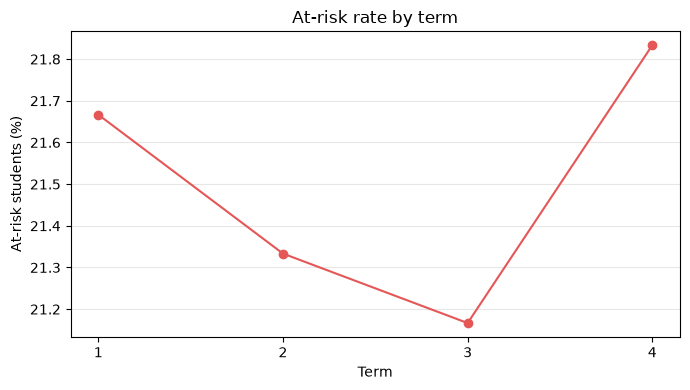

,term,at_risk_rate
0,1,0.216667
1,2,0.213333
2,3,0.211667
3,4,0.218333


In [ ]:
term_rates = df.groupby("term", as_index=False)["at_risk"].mean()
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(term_rates["term"], term_rates["at_risk"] * 100, marker="o", color="#E45756")
ax.set(
    title="At-risk rate by term",
    xlabel="Term",
    ylabel="At-risk students (%)",
    xticks=term_rates["term"],
)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "at_risk_rate_by_term.png", dpi=150, bbox_inches="tight")
plt.show()
display(term_rates.assign(at_risk_rate=term_rates.pop("at_risk")).rename(
    columns={"at_risk_rate": "at_risk_rate"}
))

**Takeaway:** Term-level rates help monitor cohort variation, but term is excluded from model inputs to avoid relying on cohort identity.

## Leakage awareness

- **`next_score` cannot be a feature:** it is the week-10 outcome being predicted and is not known at the end-of-week-8 checkpoint; using it would leak the answer.
- **`student_id` cannot be a feature:** it is an identifier, not an educational signal. A model could memorize individuals or exploit row/order patterns instead of generalizing to new students.
- **`term` cannot be a feature:** cohort identity may encode time-specific conditions and let a model exploit cohort artifacts. Use it for descriptive monitoring and appropriate splitting, not as a predictor.

Only week-1-to-week-8 educational indicators are eligible predictors. The tool remains advisory: teachers and counsellors review context and decide whether to offer support.